In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

2026-10-16 11:38:19.490738: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-16 11:38:19.869687: I tensorflow/core/util/util.cc:169] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-16 11:38:23.921000: I tensorflow/c/logging.cc:34] Successfully opened dynamic library libdirectml.d6f03b303ac3c4f2eeb8ca631688c9757b361310.so
2026-10-16 11:38:23.921280: I tensorflow/c/logging.cc:34] Successfully opened dynamic library libdxcore.so
2026-10-16 11:38:23.932285: I tensorflow/c/logging.cc:34] Successfully opened dynamic library libd

In [3]:
dataset = load_breast_cancer()

X = dataset.data
y = dataset.target

print("Features:", X.shape)
print("Labels:", y.shape)
print("Classes:", dataset.target_names)

Features: (569, 30)
Labels: (569,)
Classes: ['malignant' 'benign']


In [4]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.2,
    random_state=42,
    stratify=y_train_val
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (364, 30)
Validation: (91, 30)
Testing: (114, 30)


In [5]:
normalizer = layers.Normalization()
normalizer.adapt(X_train)

model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    normalizer,
    layers.Dense(16, activation="relu", name="hidden_1"),
    layers.Dense(8, activation="relu", name="hidden_2"),
    layers.Dense(1, activation="sigmoid", name="outer")
])

model.summary()

2026-10-16 11:38:26.956271: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-16 11:38:26.958865: I tensorflow/c/logging.cc:34] DirectML: creating device on adapter 0 (Intel(R) Iris(R) Xe Graphics)
2026-10-16 11:38:27.049510: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-16 11:38:27.049642: W tensorflow/core/common_runtime/pluggable_device/pluggable_device_bfc_allocator.cc:28] Overriding allow_growth setting because force_memory_growth was requested by the device.
2026-10-16 11:38:27.049751: I tensorflow/core/common_runtime/pluggable_device/plug

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalization (Normalizatio  (None, 30)               61        
 n)                                                              
                                                                 
 hidden_1 (Dense)            (None, 16)                496       
                                                                 
 hidden_2 (Dense)            (None, 8)                 136       
                                                                 
 outer (Dense)               (None, 1)                 9         
                                                                 
Total params: 702
Trainable params: 641
Non-trainable params: 61
_________________________________________________________________


In [14]:
print(X_train)

[[1.480e+01 1.766e+01 9.588e+01 ... 8.308e-02 3.600e-01 7.285e-02]
 [1.174e+01 1.402e+01 7.424e+01 ... 8.290e-02 3.101e-01 6.688e-02]
 [1.471e+01 2.159e+01 9.555e+01 ... 1.834e-01 3.698e-01 1.094e-01]
 ...
 [1.444e+01 1.518e+01 9.397e+01 ... 1.599e-01 2.691e-01 7.683e-02]
 [1.742e+01 2.556e+01 1.145e+02 ... 1.099e-01 1.603e-01 6.818e-02]
 [1.143e+01 1.731e+01 7.366e+01 ... 6.402e-02 2.584e-01 8.096e-02]]


In [15]:
print(dataset)

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]]), 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
 

In [6]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50


2026-10-16 11:38:28.131964: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-16 11:38:28.196898: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-16 11:38:28.197005: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 6941 MB memory) -> physical PluggableDevice (device: 0, name: DML, pci bus id: <undefined>)


12/12 [==============================] - 2s 66ms/step - loss: 0.7443 - accuracy: 0.3242 - val_loss: 0.7105 - val_accuracy: 0.4286
Epoch 2/50
 8/12 [===================>..........] - ETA: 0s - loss: 0.6623 - accuracy: 0.6055

2026-10-16 11:38:29.476696: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-16 11:38:29.508469: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-16 11:38:29.508536: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 6941 MB memory) -> physical PluggableDevice (device: 0, name: DML, pci bus id: <undefined>)


12/12 [==============================] - 0s 20ms/step - loss: 0.6473 - accuracy: 0.6511 - val_loss: 0.6346 - val_accuracy: 0.6813
Epoch 3/50
12/12 [==============================] - 0s 21ms/step - loss: 0.5637 - accuracy: 0.8269 - val_loss: 0.5559 - val_accuracy: 0.8242
Epoch 4/50
12/12 [==============================] - 0s 21ms/step - loss: 0.4839 - accuracy: 0.8791 - val_loss: 0.4807 - val_accuracy: 0.8681
Epoch 5/50
12/12 [==============================] - 0s 22ms/step - loss: 0.4102 - accuracy: 0.9066 - val_loss: 0.4127 - val_accuracy: 0.8791
Epoch 6/50
12/12 [==============================] - 0s 18ms/step - loss: 0.3477 - accuracy: 0.9231 - val_loss: 0.3572 - val_accuracy: 0.8791
Epoch 7/50
12/12 [==============================] - 0s 22ms/step - loss: 0.2996 - accuracy: 0.9286 - val_loss: 0.3126 - val_accuracy: 0.8901
Epoch 8/50
12/12 [==============================] - 0s 21ms/step - loss: 0.2616 - accuracy: 0.9423 - val_loss: 0.2746 - val_accuracy: 0.9011
Epoch 9/50
12/12 [======

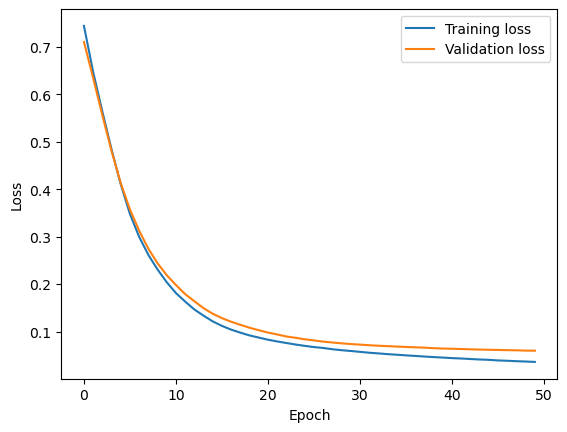

In [8]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test loss:", test_loss)
print("Tet accuracy:", test_accuracy)

Test loss: 0.07596417516469955
Tet accuracy: 0.9649122953414917


In [10]:
probabilities = model.predict(X_test[:2], verbose=0)

predicted_classes = (probabilities >= 0.5).astype(int)

print("Probabilities:", probabilities.ravel())
print("Predicted labels:", predicted_classes.ravel()),
print("Actual labels:", y_test[:2])

Probabilities: [2.9403705e-07 9.9996471e-01]
Predicted labels: [0 1]
Actual labels: [0 1]


2026-10-16 11:38:44.116810: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


In [11]:
model.save("models/t5_k_f_br_cancer_model.keras")

In [12]:
loaded_model = keras.models.load_model(
    "models/t5_k_f_br_cancer_model.keras"
)

loaded_predictions = loaded_model.predict(
    X_test[:10],
    verbose=0
)

print("Predictions from loaded models:")
print(loaded_predictions.ravel())

Predictions from loaded models:
[2.9403705e-07 9.9996471e-01 1.7390231e-03 4.4606006e-01 3.9846732e-06
 9.9461174e-01 9.9996626e-01 2.5326317e-05 4.6275635e-04 2.5865032e-10]


2026-10-16 11:38:44.405973: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


In [13]:
loaded_predicted_classes = (loaded_predictions >= 0.5).astype(int)

print("Classes")
print(loaded_predicted_classes.ravel())

Classes
[0 1 0 0 0 1 1 0 0 0]
